# Baselines: text-only subreddits

Harness for `textonly_baselines.py`. The module holds the data loading, features, models, and plots;
this notebook sets the configuration, runs them, and shows the results.

**Goal:** compare linear, neural, and tree models, and measure
what each feature group adds, especially **timing**, the proposal's main question.

| # | Model | Uses |
|---|---|---|
| 0 | Constant (training base rate) | nothing |
| 1 | Subreddit × weekday × hour rate | subreddit, local time |
| 2 | Naive Bayes | text |
| 3 | Logistic regression | metadata (subreddit, timing, structure, history) |
| 4 | Logistic regression | text |
| 5 | Logistic regression | metadata + text |
| 6 | MLP, one hidden layer | metadata + text |
| 7 | Random forest | metadata |
| 8 | Histogram gradient boosting | metadata |

## Design

- **Data:** all text posts from the seven subreddits (`textonly_data.py`), NSFW and deleted posts removed.
- **Label:** success = engagement above the 90th percentile of the post's **subreddit and quarter**.
  `engagement = ln(1 + score) + ln(1 + comments)`.
- **Split by time:** train before `train_end`, validate from `train_end` to `val_end`, test after.
  Defaults: train ≤ 2023, validation 2024, test 2025-01 to 2026-02.
- **Sample:** at most `max_train_per_sub` training posts and `max_eval_per_sub` validation/test posts per
  subreddit, so AskReddit does not dominate. Pooled metrics weight the subreddits about equally (small
  subreddits contribute fewer posts); per-subreddit metrics are also reported.
- **Features (only information known at posting time):**
  - `subreddit`: one-hot.
  - `timing`: local hour, weekday, and month (one-hot); posts in the subreddit in the previous hour and day
    (competition); smoothed training success rates per subreddit × hour and subreddit × weekday × hour.
  - `structure`: title length and words, body length, flags (question, number, all caps, URL, flair).
  - `history`: the author's earlier posts in the subreddit, and whether the title is a repost.
  - `text`: TF-IDF of the title and the body **before the first EDIT marker** (edits added after posting leak
    the outcome; see `textonly_eda.ipynb`, section 11).
- **Metrics:** main metric PR-AUC (a random model scores the base rate, about 0.10). Also ROC-AUC and log
  loss. Per subreddit, **lift** = PR-AUC / base rate. Choose models on validation; look at test at the end.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import textonly_baselines as tb
import textonly_data as td

td.set_style()
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Configuration and data

In [2]:
cfg = tb.Config(
    source="local",
    label_metric="engagement",
    success_quantile=0.9,
    period="quarter",
    train_end="2024-01-01",
    val_end="2025-01-01",
    max_train_per_sub=150_000,
    max_eval_per_sub=30_000,
)
cfg

Config(source='local', label_metric='engagement', success_quantile=0.9, period='quarter', min_period_posts=100, self_only=True, train_end='2024-01-01', val_end='2025-01-01', max_train_per_sub=150000, max_eval_per_sub=30000, body_chars=1000, tfidf_max_features=50000, tfidf_min_df=5, smoothing=20, seed=42)

In [3]:
data = tb.load_data(cfg)
tb.summary(data)

Cached benchmark samples and released the DuckDB connection.
{'train': 914038, 'val': 207133, 'test': 188947}


posts  ...                last
split subreddit                      ...                    
train AskReddit              150000  ... 2023-12-31 23:12:13
      Showerthoughts         150000  ... 2023-12-31 20:30:51
      TwoSentenceHorror      150000  ... 2023-12-31 23:52:43
      dadjokes               150000  ... 2023-12-31 23:53:39
      hypotheticalsituation   14038  ... 2023-12-31 23:07:50
      sysadmin               150000  ... 2023-12-31 21:14:59
      unpopularopinion       150000  ... 2023-12-31 23:13:33
val   AskReddit               30000  ... 2024-12-31 23:58:59
      Showerthoughts          30000  ... 2024-12-31 22:43:02
      TwoSentenceHorror       30000  ... 2024-12-31 23:40:56
      dadjokes                29760  ... 2024-12-31 23:13:10
      hypotheticalsituation   27373  ... 2024-12-31 23:39:29
      sysadmin                30000  ... 2024-12-31 22:49:33
      unpopularopinion        30000  ... 2024-12-31 23:55:09
test  AskReddit               30000  ... 2026-02-28 23:57:45
      Showerthoughts          12012  ... 2026-02-28 23:11:50
      TwoSentenceHorror       30000  ... 2026-02-28 23:36:06
      dadjokes                30000  ... 2026-02-28 23:55:02
      hypotheticalsituation   26935  ... 2026-02-28 23:37:50
      sysadmin                30000  ... 2026-02-28 23:54:24
      unpopularopinion        30000  ... 2026-02-28 23:21:36

[21 rows x 4 columns]

## 2. Features

In [4]:
feats = tb.build_features(data)

TF-IDF: 50,000 terms in 211s
{'subreddit': 6, 'timing': 44, 'structure': 9, 'history': 2, 'text': 50000}


## 3. Baseline ladder

In [5]:
res = tb.Results(data)
models = tb.run_ladder(data, feats, res, mlp=True, mlp_units=64, mlp_max_epochs=8, mlp_patience=2)
res.table()

epoch 1: train loss 0.3177, val PR-AUC 0.1832 (92s)
epoch 2: train loss 0.2939, val PR-AUC 0.1907 (182s)
epoch 3: train loss 0.2848, val PR-AUC 0.1893 (294s)
epoch 4: train loss 0.2753, val PR-AUC 0.1879 (441s)


,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
0 constant,0.0997,0.5000,0.3245,0.0996,0.5000,0.3242,NaN
1 subreddit x weekday x hour rate,0.1132,0.5373,0.3247,0.1076,0.5204,0.3262,NaN
2 naive bayes (text),0.1485,0.6199,0.3173,0.1535,0.6281,0.3158,0.3853
3 logreg (metadata),0.1244,0.5680,0.3235,0.1247,0.5650,0.3249,2.0332
4 logreg (text),0.1692,0.6477,0.3121,0.1789,0.6619,0.3092,6.4319
5 logreg (metadata + text),0.1829,0.6654,0.3095,0.1902,0.6758,0.3084,106.9943
"6 mlp, 1 hidden layer (metadata + text)",0.1907,0.6720,0.3080,0.1966,0.6800,0.3075,440.7021


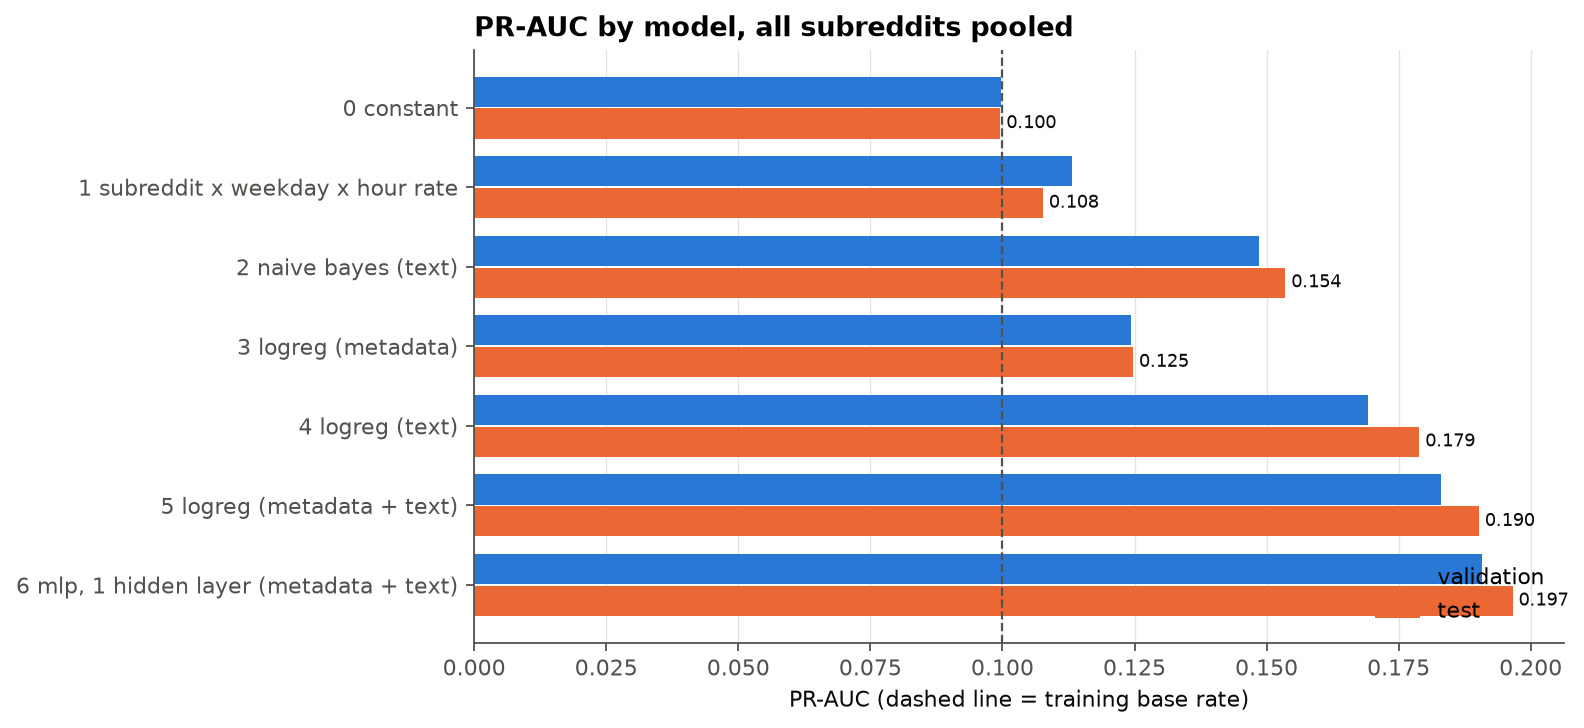

In [6]:
tb.plot_pr_auc(res);

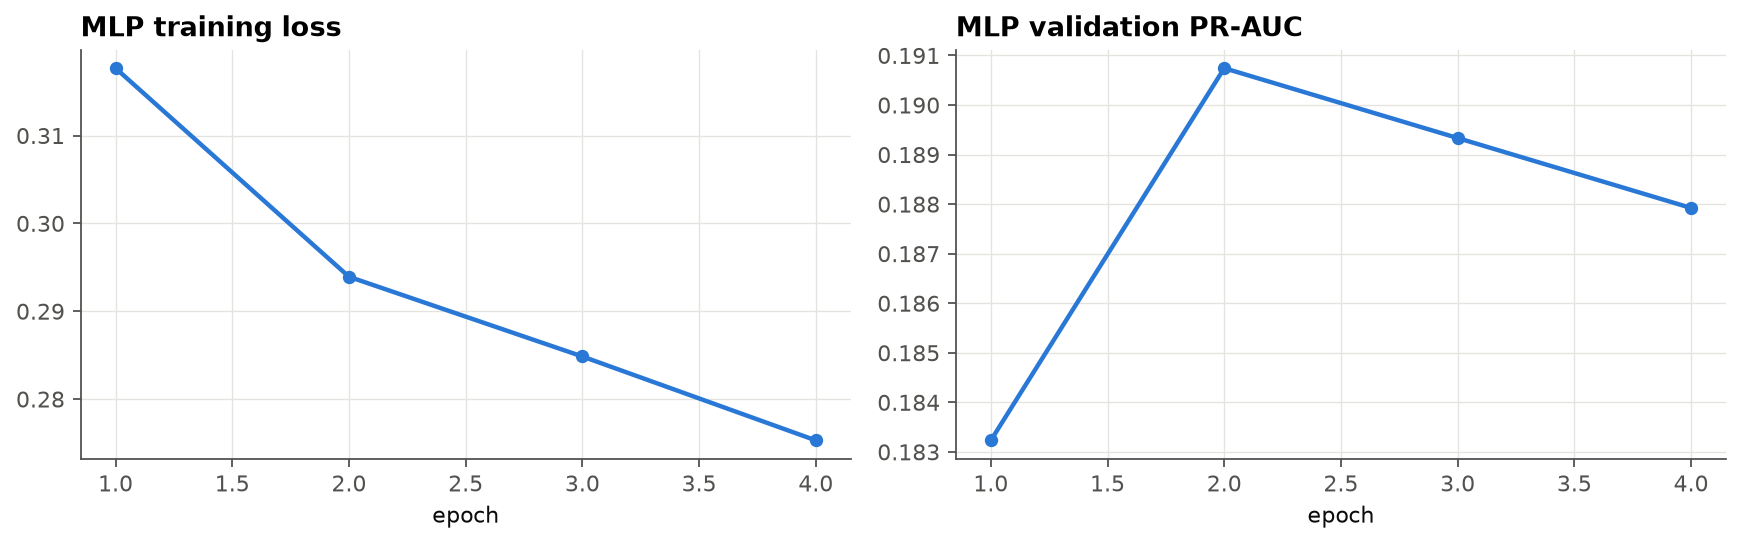

In [7]:
h = models["mlp_history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h.epoch, h.train_loss, color=td.BLUE, marker="o", markersize=5); axes[0].set_title("MLP training loss")
axes[1].plot(h.epoch, h.val_pr_auc, color=td.BLUE, marker="o", markersize=5); axes[1].set_title("MLP validation PR-AUC")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()

### By subreddit

Lift = PR-AUC / base rate (1 = no better than random). Pooled numbers can hide that a model works well in
one subreddit and not at all in another.

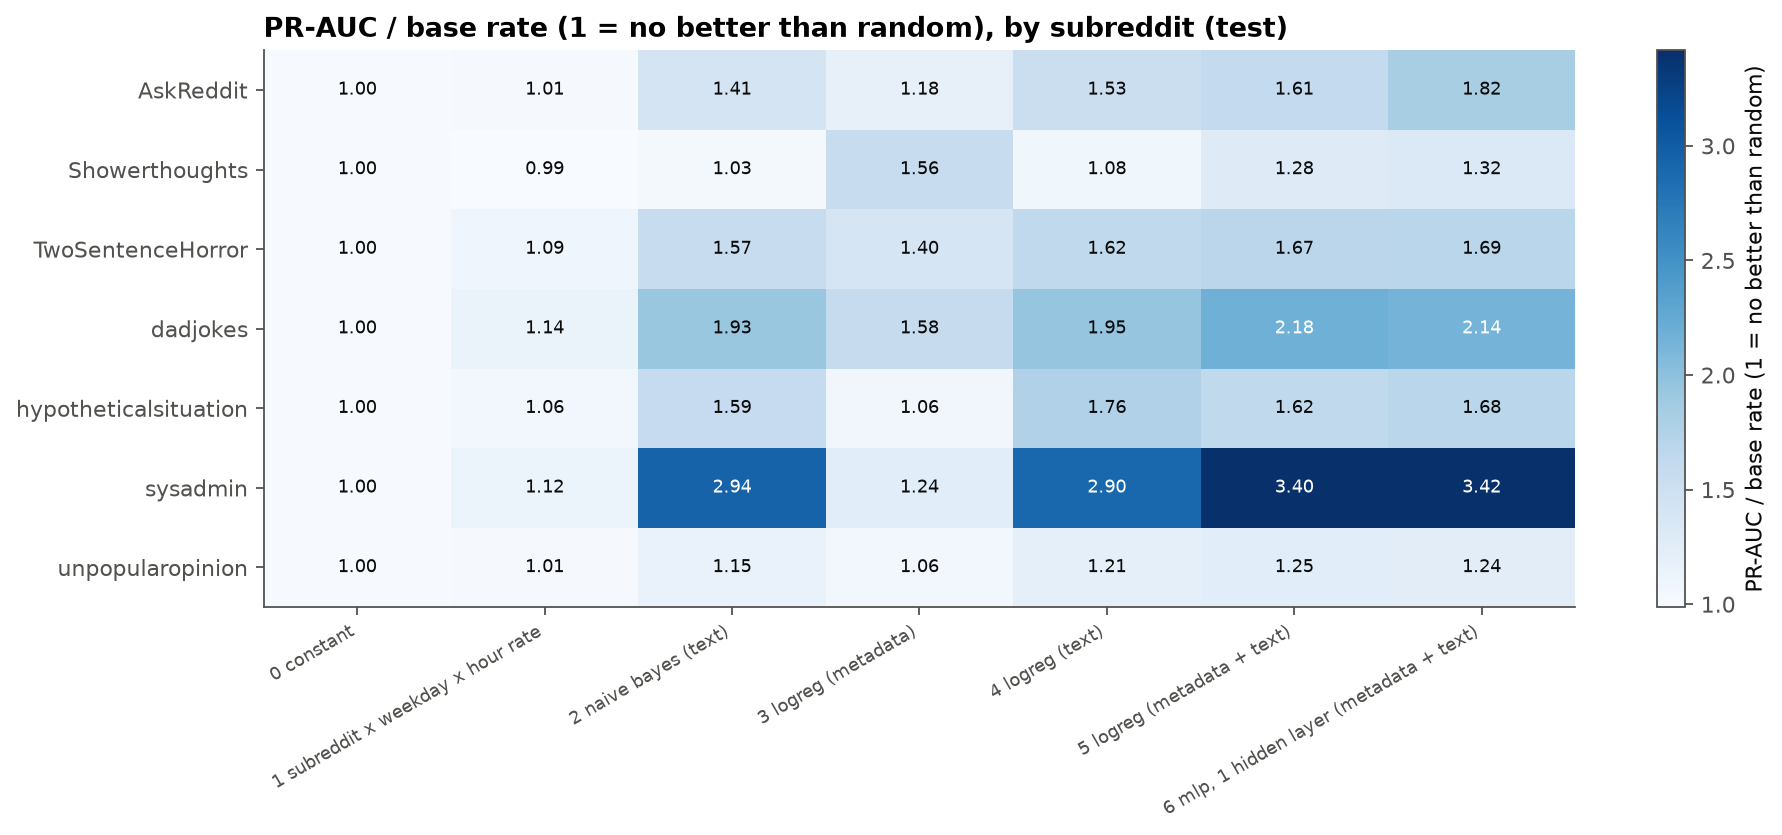

In [8]:
tb.plot_per_subreddit(res, "test", "lift");

In [9]:
res.per_subreddit("test", "pr_auc")

model,0 constant,1 subreddit x weekday x hour rate,2 naive bayes (text),3 logreg (metadata),4 logreg (text),5 logreg (metadata + text),"6 mlp, 1 hidden layer (metadata + text)"
subreddit,,,,,,,
AskReddit,0.1005,0.1019,0.1417,0.1191,0.1542,0.1617,0.1830
Showerthoughts,0.1001,0.0988,0.1028,0.1566,0.1079,0.1285,0.1322
TwoSentenceHorror,0.0976,0.1069,0.1528,0.1370,0.1585,0.1631,0.1645
dadjokes,0.0993,0.1132,0.1921,0.1571,0.1936,0.2164,0.2129
hypotheticalsituation,0.1001,0.1058,0.1592,0.1066,0.1766,0.1624,0.1682
sysadmin,0.1003,0.1120,0.2950,0.1248,0.2911,0.3412,0.3429
unpopularopinion,0.0994,0.1008,0.1143,0.1055,0.1203,0.1241,0.1229


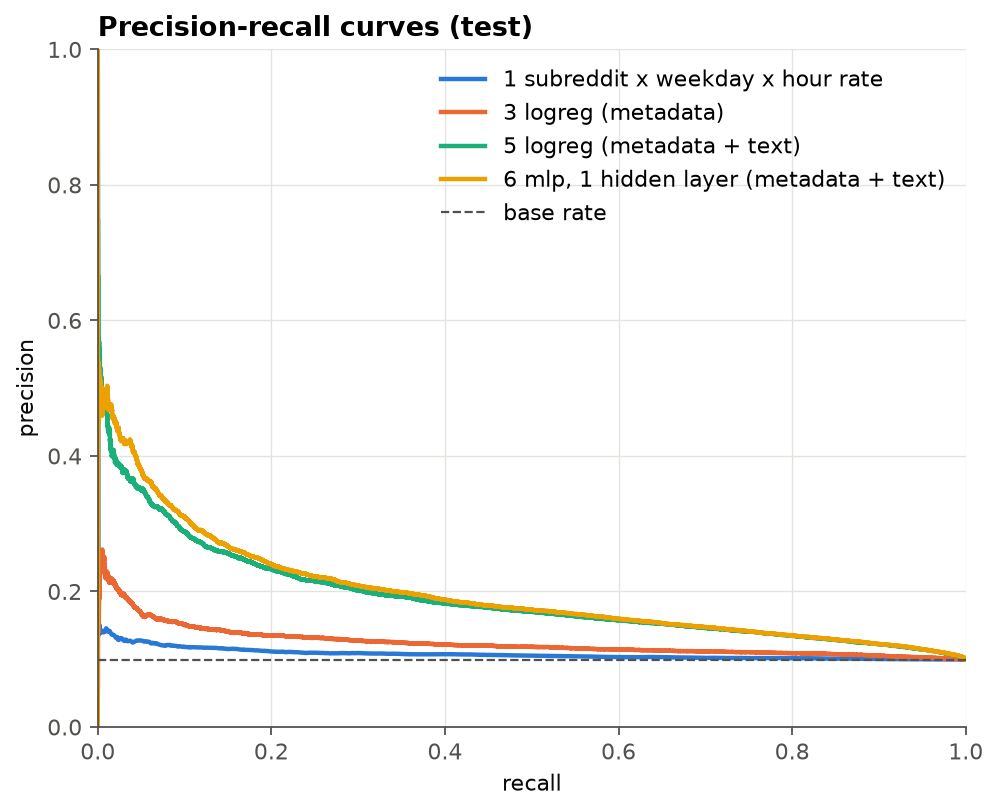

In [10]:
tb.plot_pr_curves(res, ["1 subreddit x weekday x hour rate", "3 logreg (metadata)", "5 logreg (metadata + text)",
                        "6 mlp, 1 hidden layer (metadata + text)"]);

### What the linear models learned

Metadata features are standardized, so coefficient sizes are comparable. One-hot groups drop their first
category (hour 0, Monday, January, the first subreddit alphabetically), so those coefficients are relative to it.

In [11]:
tb.coefficients(models["lr_meta"], feats, tb.META, top=15)

,coefficient
subreddit_hypotheticalsituation,-0.4965
subreddit_sysadmin,-0.3145
subreddit_TwoSentenceHorror,-0.2884
has_body,-0.2374
log_posts_prev_hour,-0.2278
subreddit_Showerthoughts,-0.2266
subreddit_dadjokes,-0.1786
local_hour_6,-0.1389
local_hour_7,-0.1387
subreddit_unpopularopinion,-0.1364


In [12]:
tb.top_terms(models["lr_text"], feats, n=25)

,most negative,most positive
0,hi,sysadmin
1,what if,sysadmins
2,is there,rant
3,story,your username
4,error,video game
5,help,friday
6,hello,email
7,question,microsoft
8,thanks,admin
9,however,ransomware


## 4. Ablation: what each feature group adds

Logistic regression on growing feature sets. The key comparison for the proposal is
**content** vs. **content + timing**: the gain is what timing adds once the text and structure of the
post are known.

In [13]:
ablation, ablation_res = tb.run_ablation(data, feats)
ablation

,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
subreddit only,0.0998,0.5011,0.3245,0.0998,0.5006,0.3242,0.7402
+ timing,0.1145,0.5427,0.3245,0.1087,0.5253,0.3260,1.5606
+ structure,0.1087,0.5358,0.3242,0.1160,0.5560,0.3227,1.8754
+ history,0.1179,0.5538,0.3232,0.1182,0.5571,0.3228,1.0551
+ text,0.1802,0.6520,0.3115,0.1951,0.6675,0.3077,23.9188
content (structure + history + text),0.1862,0.6619,0.3093,0.2020,0.6830,0.3048,63.8338
content + timing (all),0.1840,0.6666,0.3092,0.1910,0.6770,0.3082,93.5302


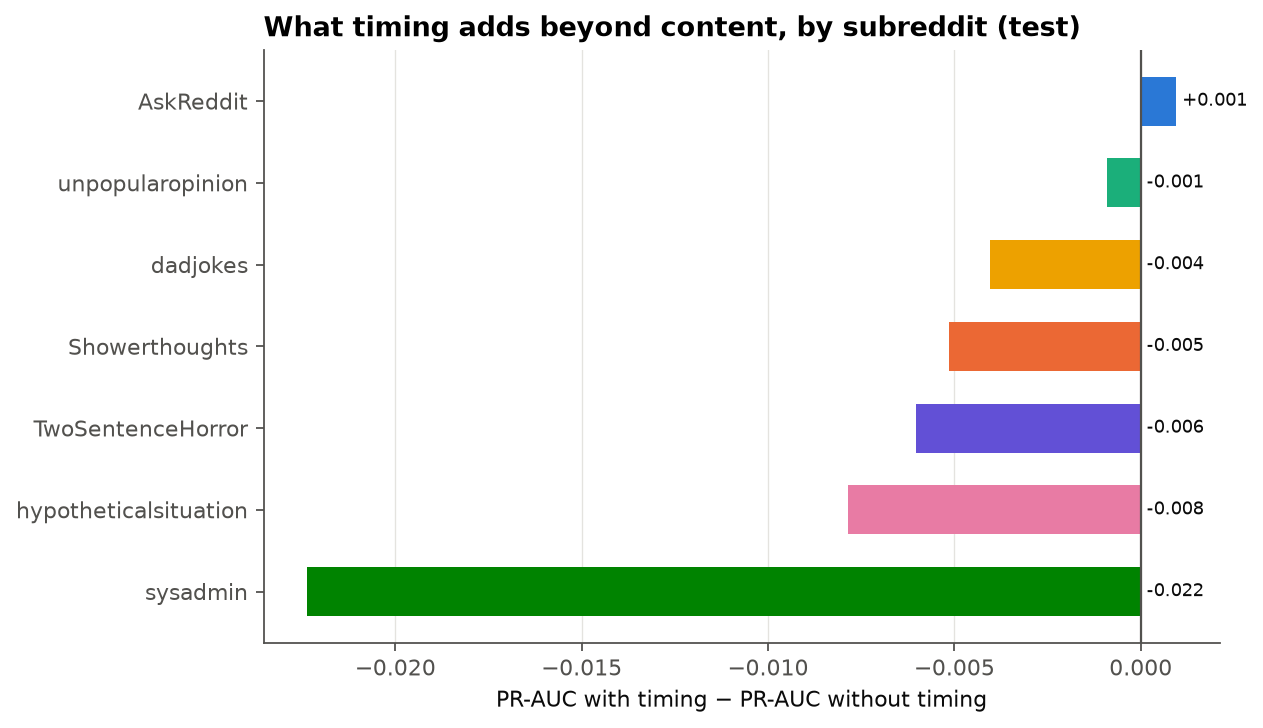

In [14]:
tb.plot_timing_gain(ablation_res, "test");

In [15]:
ablation_res.per_subreddit("test", "pr_auc")

model,subreddit only,+ timing,+ structure,+ history,+ text,content (structure + history + text),content + timing (all)
subreddit,,,,,,,
AskReddit,0.1005,0.1036,0.0757,0.1516,0.1604,0.1634,0.1643
Showerthoughts,0.1001,0.0959,0.1265,0.1572,0.1079,0.1329,0.1277
TwoSentenceHorror,0.0976,0.1097,0.1465,0.1248,0.1557,0.1697,0.1637
dadjokes,0.0993,0.1160,0.1658,0.1226,0.1952,0.2199,0.2158
hypotheticalsituation,0.1001,0.1080,0.1069,0.0847,0.1586,0.1710,0.1632
sysadmin,0.1003,0.1131,0.1288,0.1095,0.3687,0.3662,0.3439
unpopularopinion,0.0994,0.1025,0.1043,0.1061,0.1235,0.1254,0.1245


## 5. Random forest and gradient boosting

These classifiers use the same **metadata** groups and sampled posts as model 3 (metadata logistic
regression): subreddit, timing, structure, and history. This comparison tests whether tree interactions
capture patterns that a linear model misses. TF-IDF is excluded; only the small metadata matrix is made
dense for histogram boosting.

Defaults limit tree size. Boosting uses 200 fixed iterations with automatic early stopping disabled, so
it does not create a random internal validation split. Tune the overrides below on **2024 validation**.
Executed on the full extract; the comparisons below include models 0-8.


In [16]:
tree_models = tb.run_tree_models(
    data, feats, res,
    rf_params={"n_estimators": 300, "max_depth": 20, "min_samples_leaf": 50},
    gb_params={"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 31,
               "min_samples_leaf": 50, "l2_regularization": 1.0},
)
models.update(tree_models)
res.table()


7 random forest (metadata): fit in 61.5s
8 gradient boosting (metadata): fit in 22.7s


,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
0 constant,0.0997,0.5000,0.3245,0.0996,0.5000,0.3242,NaN
1 subreddit x weekday x hour rate,0.1132,0.5373,0.3247,0.1076,0.5204,0.3262,NaN
2 naive bayes (text),0.1485,0.6199,0.3173,0.1535,0.6281,0.3158,0.3853
3 logreg (metadata),0.1244,0.5680,0.3235,0.1247,0.5650,0.3249,2.0332
4 logreg (text),0.1692,0.6477,0.3121,0.1789,0.6619,0.3092,6.4319
5 logreg (metadata + text),0.1829,0.6654,0.3095,0.1902,0.6758,0.3084,106.9943
"6 mlp, 1 hidden layer (metadata + text)",0.1907,0.6720,0.3080,0.1966,0.6800,0.3075,440.7021
7 random forest (metadata),0.1397,0.5998,0.3187,0.1380,0.5952,0.3194,61.5327
8 gradient boosting (metadata),0.1446,0.6108,0.3175,0.1434,0.6077,0.3184,22.6581


In [17]:
# Direct comparison on the same metadata features
res.table().loc[["3 logreg (metadata)", "7 random forest (metadata)", "8 gradient boosting (metadata)"]]


,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
3 logreg (metadata),0.1244,0.5680,0.3235,0.1247,0.5650,0.3249,2.0332
7 random forest (metadata),0.1397,0.5998,0.3187,0.1380,0.5952,0.3194,61.5327
8 gradient boosting (metadata),0.1446,0.6108,0.3175,0.1434,0.6077,0.3184,22.6581


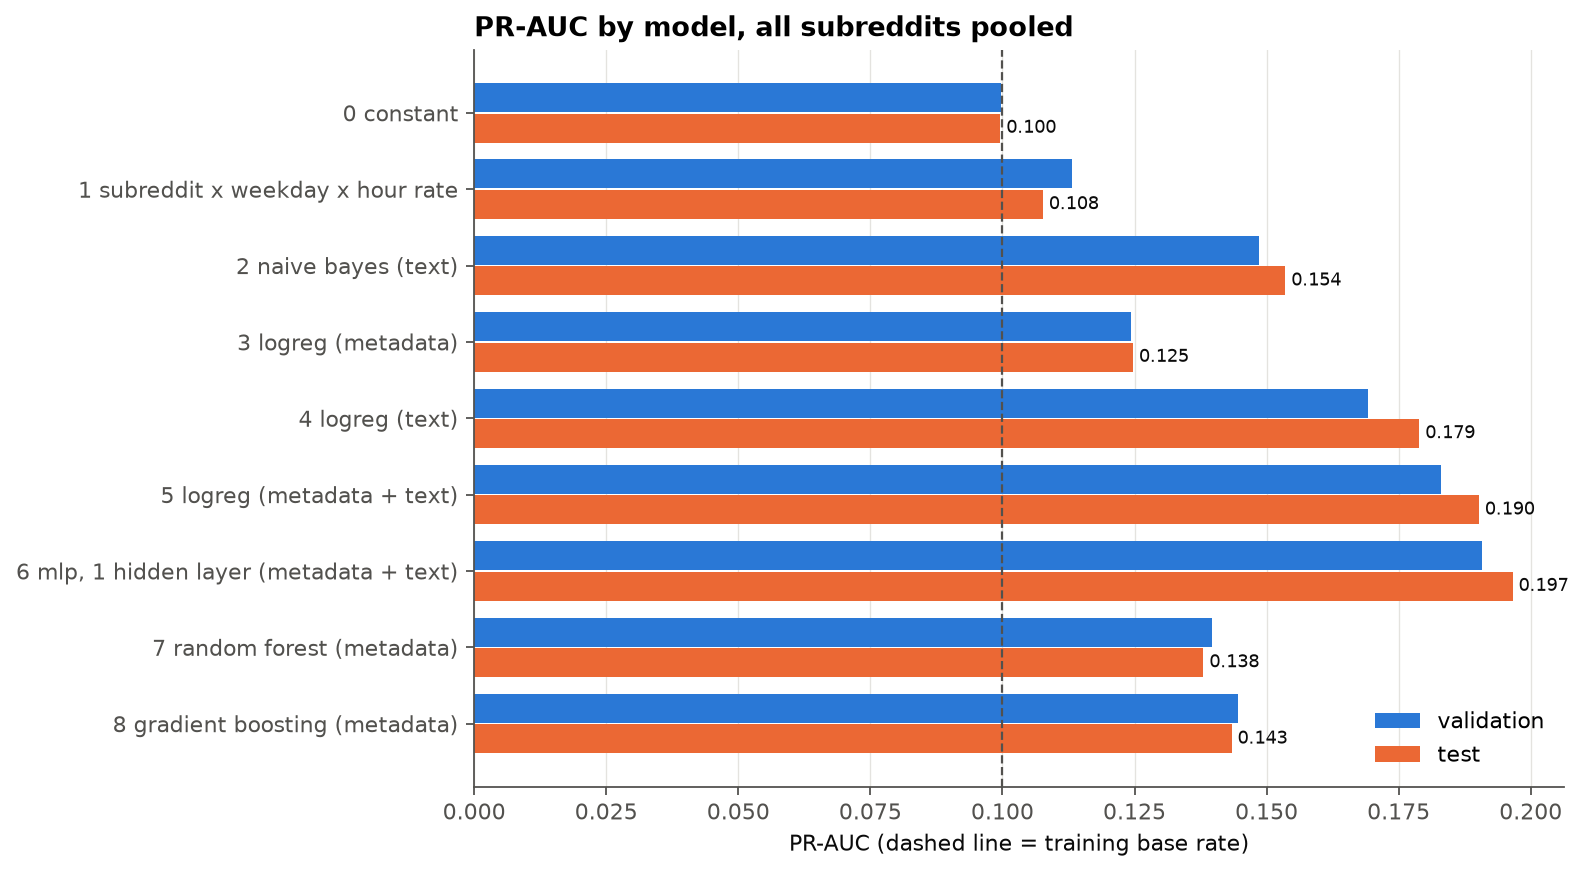

In [18]:
tb.plot_pr_auc(res);


In [19]:
# All seven subreddits, including the earlier baselines
res.per_subreddit("test", "pr_auc")


model,0 constant,1 subreddit x weekday x hour rate,2 naive bayes (text),3 logreg (metadata),4 logreg (text),5 logreg (metadata + text),"6 mlp, 1 hidden layer (metadata + text)",7 random forest (metadata),8 gradient boosting (metadata)
subreddit,,,,,,,,,
AskReddit,0.1005,0.1019,0.1417,0.1191,0.1542,0.1617,0.1830,0.1554,0.1543
Showerthoughts,0.1001,0.0988,0.1028,0.1566,0.1079,0.1285,0.1322,0.1321,0.1401
TwoSentenceHorror,0.0976,0.1069,0.1528,0.1370,0.1585,0.1631,0.1645,0.1445,0.1470
dadjokes,0.0993,0.1132,0.1921,0.1571,0.1936,0.2164,0.2129,0.1618,0.1639
hypotheticalsituation,0.1001,0.1058,0.1592,0.1066,0.1766,0.1624,0.1682,0.1258,0.1463
sysadmin,0.1003,0.1120,0.2950,0.1248,0.2911,0.3412,0.3429,0.1443,0.1585
unpopularopinion,0.0994,0.1008,0.1143,0.1055,0.1203,0.1241,0.1229,0.1067,0.1057


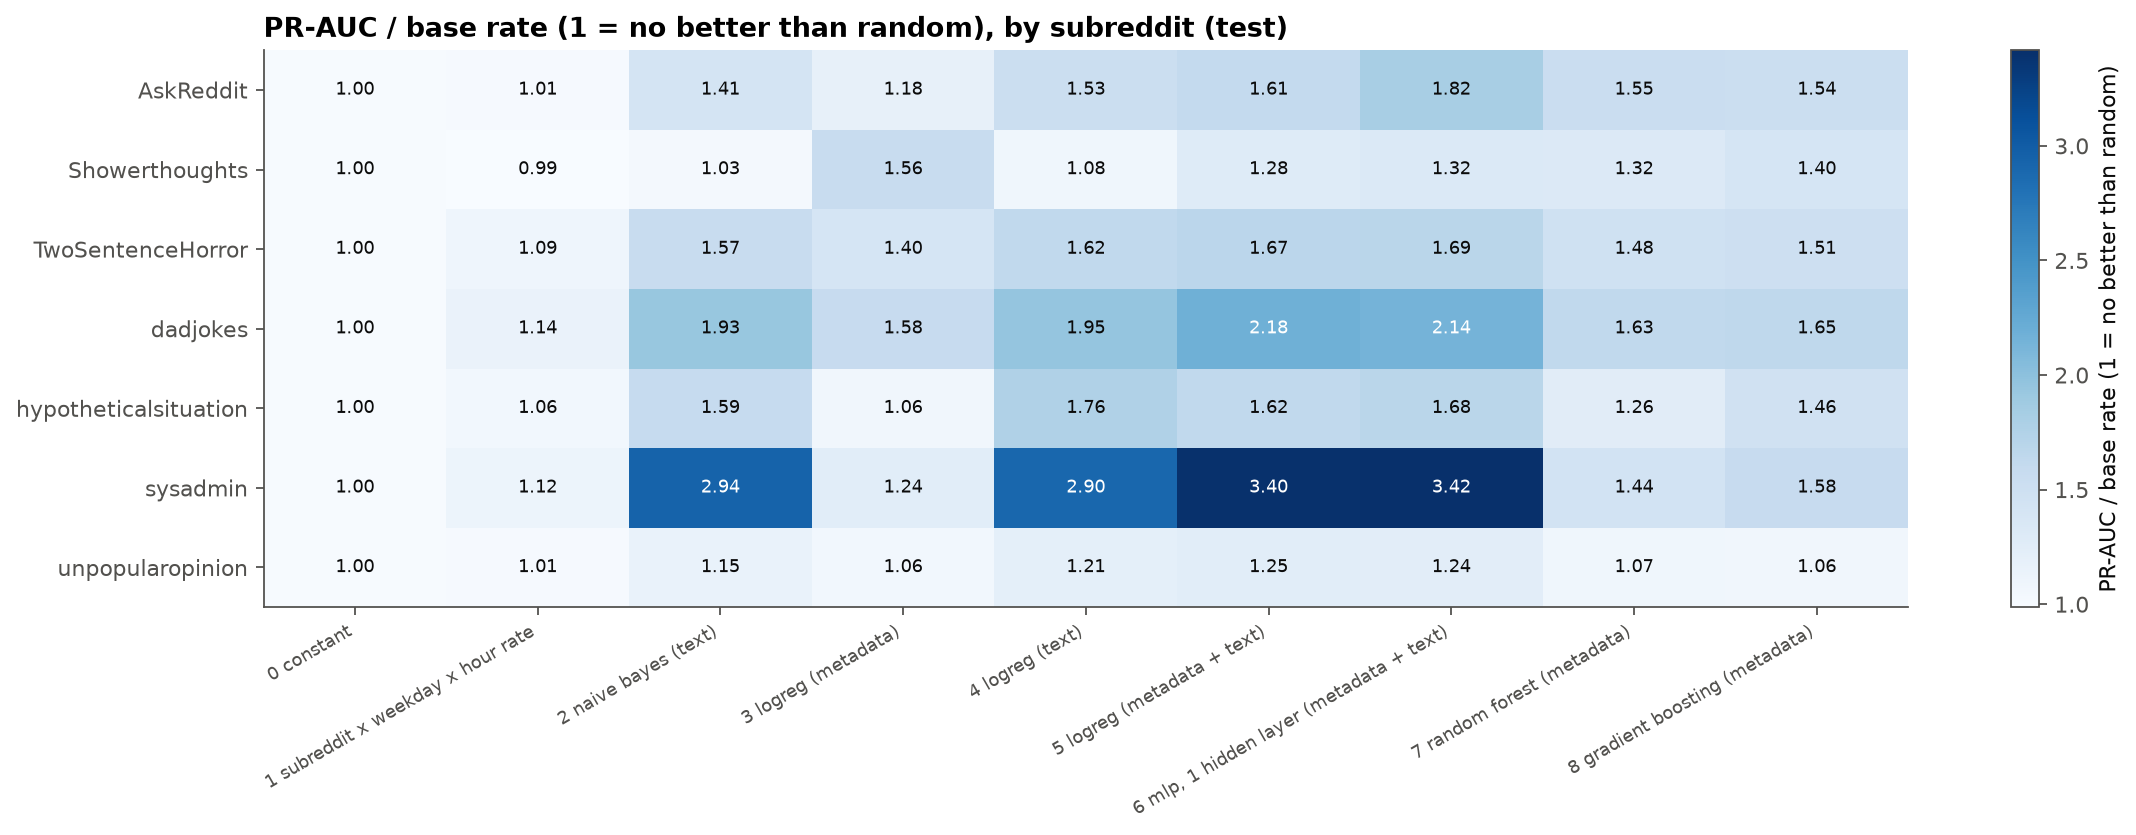

In [20]:
tb.plot_per_subreddit(res, "test", "lift");


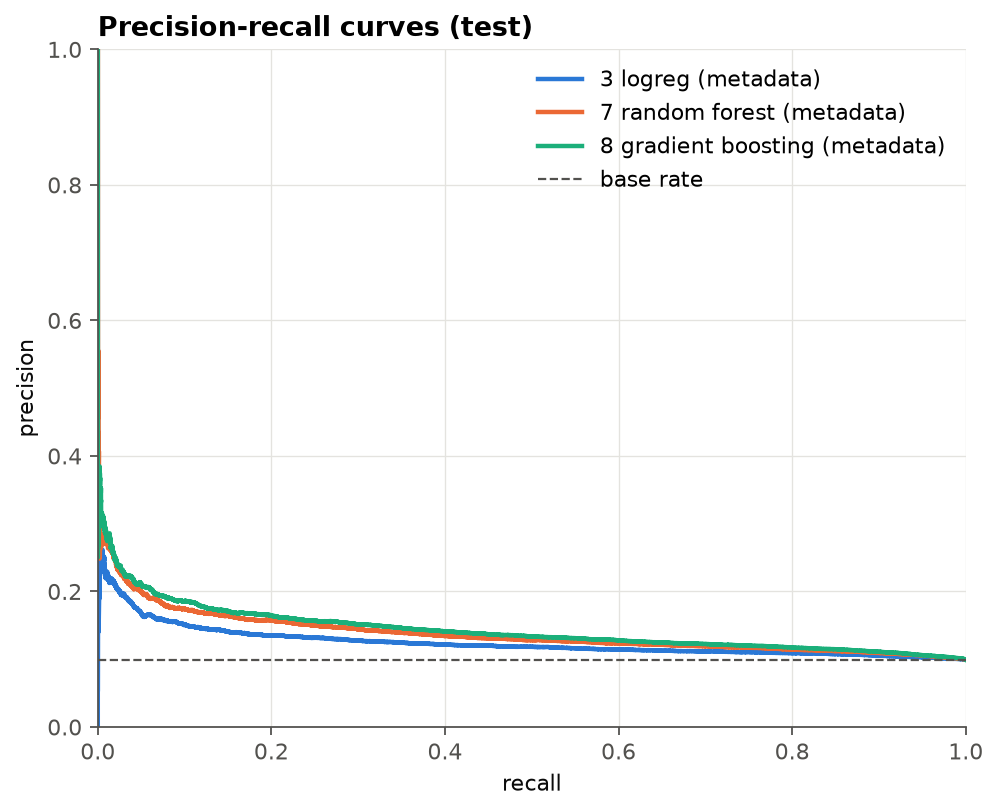

In [21]:
tb.plot_pr_curves(res, ["3 logreg (metadata)", "7 random forest (metadata)",
                        "8 gradient boosting (metadata)"]);


## Next steps

- **Tree tuning:** tune random forest and gradient boosting on validation only. Compare the metadata
  models directly before adding text features or extending the timing ablation to trees.
- **Text embeddings:** add an `embeddings` group (for example `all-MiniLM-L6-v2` on title + clean body) and
  compare it with `text` (TF-IDF) in the ablation. If embeddings do not beat TF-IDF, they are not needed.
- **Other tuning on validation only:** `C`, TF-IDF size, MLP units and regularization. Existing test
  results are exploratory; do not use test metrics to guide further model selection.
- **Threshold metrics** (precision, recall, F1) at a threshold chosen on validation, as the proposal asks.
